# ResNeSt — Split-Attention Networks

**Paper:** Zhang, H., Wu, C., Zhang, Z., Zhu, Y., Zhang, Z., Lin, H., ... & Smola, A. J. (2020).  
*ResNeSt: Split-Attention Networks.*  
arXiv:2004.08955. [[PDF]](https://arxiv.org/abs/2004.08955)

**Affiliation:** Amazon Web Services (AWS AI Labs)

---

## Overview

ResNeSt extends ResNet by introducing **Split-Attention**: a per-channel attention mechanism
over multiple feature map *splits* (branches).  Unlike SE-Net which performs global channel
attention, ResNeSt performs group-wise attention over radix splits.

Key difference from other attention mechanisms:
- **SE-Net**: channel attention, one global weight per channel
- **CBAM**: spatial + channel attention
- **ResNeSt**: attention across radix feature splits (like Selective Kernel generalised)

ResNeSt achieves state-of-the-art results on detection/segmentation tasks when used
as a backbone (Detectron2, ADE20K, Cityscapes).

> 📄 **Paper:** Zhang et al. (2022). ResNeSt: Split-Attention Networks. CVPR Workshops 2022.
> 🔗 **Link:** <https://arxiv.org/abs/2004.08955>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/resnest.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> STEM["deep stem: 3 × conv 3×3 · maxpool /4"]:::stage --> S["Split-Attention bottleneck stages ×[3,4,6,3]"]:::stage --> GAP["avg pool"]:::block --> OUT
  subgraph SA["Split-Attention (radix r, cardinality k)"]
    direction LR
    X["x"] --> GC["grouped conv → r splits"]:::block --> SUM["Σ splits → GAP → FC · BN · ReLU"]:::block
    SUM --> RS["FC → r-softmax per cardinal group"]:::block --> WS["Σ_r a_r · split_r"]:::block
    GC --> WS
  end
  S -.-> SA
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture (ASCII)

### Split-Attention Conv2d (radix=2)
```
Input X [B, C_in, H, W]
    │
    ▼
  Conv(C_in → C_out × radix, groups=radix)   ← produce radix=2 branches
  BN + ReLU
  reshape → [B, radix=2, C_out, H, W]        U₁, U₂
    │
    ▼
  V = U₁ + U₂   (element-wise sum)           [B, C_out, H, W]
    │
    ▼
  s = GlobalAvgPool(V)                        [B, C_out, 1, 1]
  s = BN(s)
  s = FC(C_out → C_out//4) → ReLU            bottleneck
  s = FC(C_out//4 → C_out × radix)           split scores
  reshape → [B, radix=2, C_out, 1, 1]
  softmax over radix axis → a₁, a₂           attention weights
    │
    ▼
  Output = a₁ × U₁ + a₂ × U₂               [B, C_out, H, W]
```

### ResNeSt Bottleneck
```
input ─────────────────────────────── (+) ──→ ReLU
  ↓                                    ↑
  Conv 1×1 + BN + ReLU            (downsample?)
  ↓
  SplitAttentionConv2d(3×3)  ← replaces standard 3×3
  ↓
  ReLU
  ↓
  Conv 1×1 + BN
  ─────────────────────────────────────┘
```

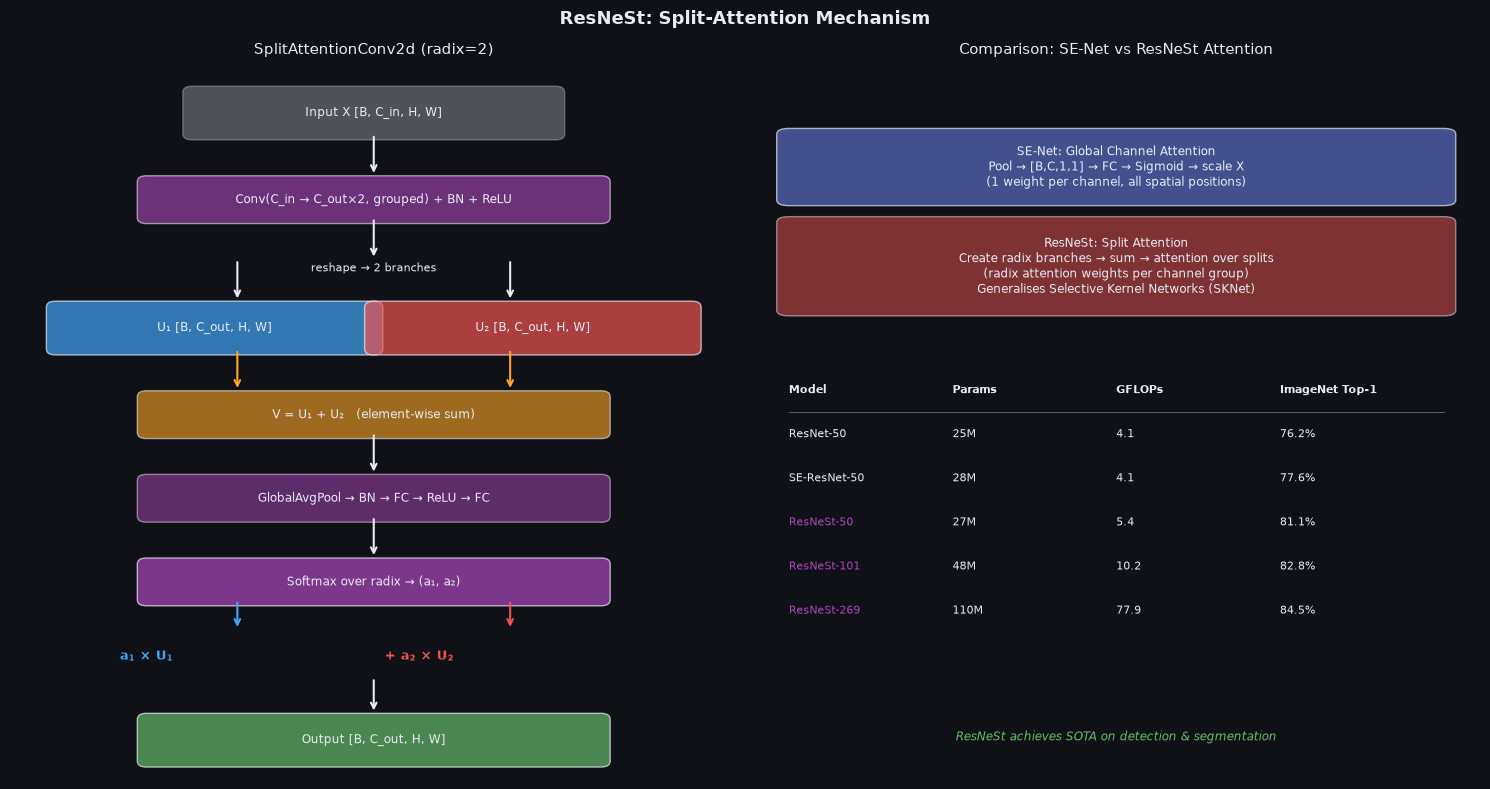

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np

BG   = '#0f1117'
FG   = '#e8eaf6'
BR1  = '#42a5f5'  # branch 1
BR2  = '#ef5350'  # branch 2
ATT  = '#ab47bc'  # attention
SUM  = '#ffa726'  # sum
OUT  = '#66bb6a'  # output

fig, axes = plt.subplots(1, 2, figsize=(15, 8), facecolor=BG)
fig.suptitle('ResNeSt: Split-Attention Mechanism', color=FG, fontsize=13, fontweight='bold')

# ── Left: Split-Attention diagram ─────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG); ax.set_xlim(0, 8); ax.set_ylim(0, 12); ax.axis('off')
ax.set_title('SplitAttentionConv2d (radix=2)', color=FG, fontsize=11)

def box(ax, x, y, w, h, text, color, alpha=0.7, fs=8.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.1', fc=color, alpha=alpha, ec=FG, lw=1))
    ax.text(x+w/2, y+h/2, text, ha='center', va='center', color=FG, fontsize=fs)

def arr(ax, x, y1, y2, color=FG):
    ax.annotate('', xy=(x, y2), xytext=(x, y1), arrowprops=dict(arrowstyle='->', color=color, lw=1.5))

# Input
box(ax, 2.0, 10.8, 4, 0.7, 'Input X [B, C_in, H, W]', FG, alpha=0.3)
arr(ax, 4.0, 10.8, 10.1)
box(ax, 1.5, 9.4, 5, 0.6, 'Conv(C_in → C_out×2, grouped) + BN + ReLU', ATT, 0.6)
arr(ax, 4.0, 9.4, 8.7)
# Split into 2 branches
ax.text(4.0, 8.5, 'reshape → 2 branches', ha='center', color=FG, fontsize=8)
arr(ax, 2.5, 8.7, 8.0)  # branch 1
arr(ax, 5.5, 8.7, 8.0)  # branch 2
box(ax, 0.5, 7.2, 3.5, 0.7, 'U₁ [B, C_out, H, W]', BR1)
box(ax, 4.0, 7.2, 3.5, 0.7, 'U₂ [B, C_out, H, W]', BR2)

# Sum for attention query
ax.annotate('', xy=(2.5, 6.5), xytext=(2.5, 7.2), arrowprops=dict(arrowstyle='->', color=SUM, lw=1.5))
ax.annotate('', xy=(5.5, 6.5), xytext=(5.5, 7.2), arrowprops=dict(arrowstyle='->', color=SUM, lw=1.5))
box(ax, 1.5, 5.8, 5, 0.6, 'V = U₁ + U₂   (element-wise sum)', SUM, 0.6)
arr(ax, 4.0, 5.8, 5.1)

# Attention branch
box(ax, 1.5, 4.4, 5, 0.6, 'GlobalAvgPool → BN → FC → ReLU → FC', ATT, 0.5)
arr(ax, 4.0, 4.4, 3.7)
box(ax, 1.5, 3.0, 5, 0.6, 'Softmax over radix → (a₁, a₂)', ATT)

# Final weighted sum
ax.annotate('', xy=(2.5, 2.5), xytext=(2.5, 3.0), arrowprops=dict(arrowstyle='->', color=BR1, lw=1.5))
ax.annotate('', xy=(5.5, 2.5), xytext=(5.5, 3.0), arrowprops=dict(arrowstyle='->', color=BR2, lw=1.5))
ax.text(1.5, 2.0, 'a₁ × U₁', ha='center', color=BR1, fontsize=9, fontweight='bold')
ax.text(4.5, 2.0, '+ a₂ × U₂', ha='center', color=BR2, fontsize=9, fontweight='bold')
arr(ax, 4.0, 1.7, 1.1)
box(ax, 1.5, 0.3, 5, 0.7, 'Output [B, C_out, H, W]', OUT)

# ── Right: Comparison with SE ──────────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG); ax2.set_xlim(0, 6); ax2.set_ylim(-1, 12); ax2.axis('off')
ax2.set_title('Comparison: SE-Net vs ResNeSt Attention', color=FG, fontsize=11)

# SE-Net summary
box(ax2, 0.3, 9.5, 5.4, 1.2, 'SE-Net: Global Channel Attention\nPool → [B,C,1,1] → FC → Sigmoid → scale X\n(1 weight per channel, all spatial positions)', '#5c6bc0')
box(ax2, 0.3, 7.5, 5.4, 1.6, 'ResNeSt: Split Attention\nCreate radix branches → sum → attention over splits\n(radix attention weights per channel group)\nGeneralises Selective Kernel Networks (SKNet)', '#ef5350', 0.5)

# Accuracy table
table_data = [
    ['Model', 'Params', 'GFLOPs', 'ImageNet Top-1'],
    ['ResNet-50', '25M', '4.1', '76.2%'],
    ['SE-ResNet-50', '28M', '4.1', '77.6%'],
    ['ResNeSt-50', '27M', '5.4', '81.1%'],
    ['ResNeSt-101', '48M', '10.2', '82.8%'],
    ['ResNeSt-269', '110M', '77.9', '84.5%'],
]
for i, row in enumerate(table_data):
    y = 6.0 - i * 0.8
    for j, cell in enumerate(row):
        x = 0.3 + j * 1.35
        color = FG if i == 0 else ('#ab47bc' if 'ResNeSt' in cell else FG)
        ax2.text(x, y, cell, color=color, fontsize=8,
                 fontweight='bold' if i == 0 else 'normal')

ax2.axhline(y=5.65, xmin=0.05, xmax=0.95, color=FG, lw=0.5, alpha=0.5)
ax2.text(3.0, -0.3, 'ResNeSt achieves SOTA on detection & segmentation', 
         ha='center', color=OUT, fontsize=8.5, style='italic')

plt.tight_layout()

plt.show()

## 3. Key ideas

## Key Innovations & Mathematics

### Split-Attention Formulation

For cardinality $K=1$, radix $r=2$, input $X \in \mathbb{R}^{B \times C \times H \times W}$:

**Step 1 — Feature Splits:**
$$\hat{U}_k = \mathcal{F}_k(X), \quad k \in \{1, \ldots, r\}$$

where $\mathcal{F}_k$ is a 3×3 grouped convolution applied to split $k$.

**Step 2 — Aggregation:**
$$V = \sum_{k=1}^{r} \hat{U}_k \quad \in \mathbb{R}^{B \times C \times H \times W}$$

**Step 3 — Soft Attention (split scores):**
$$s = \text{GlobAvgPool}(V) \in \mathbb{R}^{B \times C}$$
$$a_k = \text{Softmax}(W_2 \cdot \delta(W_1 s))_k \in \mathbb{R}^{B \times C}$$

where $W_1 \in \mathbb{R}^{C/4 \times C}$, $W_2 \in \mathbb{R}^{rC \times C/4}$.

**Step 4 — Weighted Combination:**
$$Y_c = \sum_{k=1}^{r} a_k^c \cdot \hat{U}_k^c$$

When $r=1$: reduces to standard grouped convolution.  
When $K>1$: each group of channels has independent split-attention.

### Why Softmax over Sigmoid?

Using **softmax** over radix forces the attention to be a convex combination: $\sum_k a_k = 1$.  
This means the network must *choose* which split to emphasise — a competitive, sparse pressure.  
SE-Net uses sigmoid (independent per channel), which can amplify all channels simultaneously.

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/resnest.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/resnest.py</code></summary>

```text
ResNeSt Vision Backbones
=========================

Implements the ResNeSt family (Zhang et al. 2020, "ResNeSt: Split-Attention
Networks"). arXiv:2004.08955.

Architecture
------------
ResNeSt extends ResNet by replacing the 3×3 bottleneck convolution with a
**Split-Attention** convolution, which combines grouped convolutions with
attention across splits.

Key idea: split feature maps into `radix` branches, apply convolution to each,
then use a soft-max gating mechanism to recombine them:

  Input [B, C_in, H, W]
    ↓ Conv(C_in → out*radix, groups=groups)   # create radix feature splits
    ↓ reshape to [B, radix, C_out//groups, H, W] per group
    ↓ element-wise sum across radix → [B, C_out, H, W]
    ↓ GlobalAvgPool → [B, C_out, 1, 1]
    ↓ BN → Conv(C_out → C_out//4) → ReLU → Conv(C_out//4 → C_out*radix)
    ↓ reshape → softmax over radix axis → attention weights [B, radix, C_out//groups, 1, 1]
    ↓ weighted sum of splits → [B, C_out, H, W]

This is "attention across feature splits" — different from SE (channel attention
over pooled features) or CBAM (spatial + channel).  Split attention generalises
SKNet (Selective Kernel) to multiple groups.

ResNeSt Bottleneck: SplitAttentionConv2d replaces the 3×3 conv.
Stage structure (same as ResNet):
  Stem + 4 stages with depths depending on model size.

Feature map outputs:
  feature_maps[0] → [B, 256,  H/4,  W/4]
  feature_maps[1] → [B, 512,  H/8,  W/8]
  feature_maps[2] → [B, 1024, H/16, W/16]
  feature_maps[3] → [B, 2048, H/32, W/32]

Registered names
----------------
  resnest50    — depths=[3, 4, 6, 3],  ~27M params
  resnest101   — depths=[3, 4, 23, 3], ~48M params
  resnest200   — depths=[3, 24, 36, 3],~70M params
  resnest269   — depths=[3, 30, 48, 8],~110M params

Citation
--------
  Zhang, H. et al. (2020). ResNeSt: Split-Attention Networks. arXiv:2004.08955.
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `cnn/resnest.py`, definition by definition

**`SplitAttentionConv2d`** - Convolution with split-attention (radix-wise gating).

In [5]:
class SplitAttentionConv2d(nn.Module):
    """Convolution with split-attention (radix-wise gating).

    Produces `radix` feature map splits, softmax-weights them using a global
    attention branch, then returns the weighted sum.

    Args:
        in_channels:  Input channel count.
        out_channels: Output channel count (per split, before combining).
        kernel_size:  Conv kernel size.
        stride:       Spatial stride.
        padding:      Spatial padding.
        groups:       Number of convolution groups (cardinality).
        radix:        Number of splits (default 2).
        reduction:    Reduction factor for the attention FC bottleneck.
    """

    def __init__(
        self,
        in_channels:  int,
        out_channels: int,
        kernel_size:  int = 3,
        stride:       int = 1,
        padding:      int = 1,
        groups:       int = 1,
        radix:        int = 2,
        reduction:    int = 4,
    ) -> None:
        super().__init__()
        inter_channels = max(in_channels * radix // reduction, 32)
        self.radix     = radix
        self.groups    = groups
        self.out_ch    = out_channels

        # Main conv: produces out_channels × radix feature maps
        self.conv = nn.Conv2d(
            in_channels, out_channels * radix,
            kernel_size=kernel_size, stride=stride, padding=padding,
            groups=groups * radix, bias=False,
        )
        self.bn0 = nn.BatchNorm2d(out_channels * radix)

        # Attention branch: globalpool → BN → FC → ReLU → FC → softmax
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.bn1  = nn.BatchNorm2d(out_channels)
        self.fc1  = nn.Conv2d(out_channels, inter_channels, kernel_size=1, groups=groups, bias=False)
        self.bn2  = nn.BatchNorm2d(inter_channels)
        self.fc2  = nn.Conv2d(inter_channels, out_channels * radix, kernel_size=1, groups=groups, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Produce all radix feature maps
        x   = F.relu(self.bn0(self.conv(x)), inplace=True)     # [B, C*radix, H, W]
        B, CR, H, W = x.shape
        C = self.out_ch

        if self.radix > 1:
            # Split into radix branches: [B, radix, C, H, W]
            splits = x.reshape(B, self.radix, C, H, W)
            # Sum over radix for the attention query
            gap = splits.sum(dim=1)                             # [B, C, H, W]
        else:
            gap = x

        # Attention branch
        gap = self.bn1(gap)
        gap = self.pool(gap)                                    # [B, C, 1, 1]
        gap = F.relu(self.bn2(self.fc1(gap)), inplace=True)    # [B, inter, 1, 1]
        atten = self.fc2(gap)                                   # [B, C*radix, 1, 1]

        if self.radix > 1:
            # Softmax over radix axis
            atten = atten.reshape(B, self.radix, C, 1, 1)
            atten = F.softmax(atten, dim=1)                     # [B, radix, C, 1, 1]
            # Weighted combination
            out = (splits * atten).sum(dim=1)                   # [B, C, H, W]
        else:
            out = x * torch.sigmoid(atten)

        return out.contiguous()

**`ResNeStBottleneck`** - ResNeSt Bottleneck: 1×1 → SplitAttn3×3 → 1×1 with residual.

In [6]:
class ResNeStBottleneck(nn.Module):
    """ResNeSt Bottleneck: 1×1 → SplitAttn3×3 → 1×1 with residual.

    Replaces the standard 3×3 conv of a ResNet Bottleneck with SplitAttentionConv2d.
    The 1×1 reduce and 1×1 expand convolutions are unchanged from ResNet.

    Args:
        in_planes:  Input channels.
        planes:     Bottleneck width (output = planes × 4).
        stride:     Stride for the split-attention conv.
        downsample: Projection shortcut (if needed).
        radix:      Number of split-attention branches.
        groups:     Convolution groups.
    """

    expansion: int = 4

    def __init__(
        self,
        in_planes:  int,
        planes:     int,
        stride:     int               = 1,
        downsample: Optional[nn.Module] = None,
        radix:      int               = 2,
        groups:     int               = 1,
    ) -> None:
        super().__init__()
        out_channels = planes * self.expansion

        # 1×1 reduce
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=1, bias=False)
        self.bn1   = nn.BatchNorm2d(planes)

        # 3×3 split-attention (core innovation)
        self.conv2 = SplitAttentionConv2d(
            planes, planes, kernel_size=3, stride=stride, padding=1,
            groups=groups, radix=radix,
        )

        # 1×1 expand
        self.conv3 = nn.Conv2d(planes, out_channels, kernel_size=1, bias=False)
        self.bn3   = nn.BatchNorm2d(out_channels)

        self.downsample = downsample

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = x

        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.conv2(out)                    # split-attention (already includes BN+ReLU)
        out = F.relu(out, inplace=True)
        out = self.bn3(self.conv3(out))

        if self.downsample is not None:
            identity = self.downsample(x)

        out = F.relu(out + identity, inplace=True)
        return out

**`ResNeSt`** - ResNeSt backbone with split-attention bottleneck blocks.

In [7]:
class ResNeSt(BaseVisionBackbone):
    """ResNeSt backbone with split-attention bottleneck blocks.

    Args:
        layers:     Blocks per stage (4-element list).
        radix:      Split-attention radix (default 2).
        groups:     Convolution groups (default 1).
        img_size, in_chans, drop_rate, out_indices: See BaseVisionBackbone.
    """

    arch_name:    str       = "resnest"
    embed_dim:    int       = 2048
    feature_dims: list[int] = [256, 512, 1024, 2048]

    def __init__(
        self,
        layers:      list[int],
        radix:       int  = 2,
        groups:      int  = 1,
        img_size:    int  = 224,
        in_chans:    int  = 3,
        drop_rate:   float = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans,
                         drop_rate=drop_rate, out_indices=out_indices)

        self._radix     = radix
        self._groups    = groups
        self._in_planes = 64

        # ── Stem ──────────────────────────────────────────────────────────────
        self.stem = nn.Sequential(
            nn.Conv2d(in_chans, 64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )

        # ── 4 stages ──────────────────────────────────────────────────────────
        self.stage0 = self._make_stage(64,  layers[0], stride=1)
        self.stage1 = self._make_stage(128, layers[1], stride=2)
        self.stage2 = self._make_stage(256, layers[2], stride=2)
        self.stage3 = self._make_stage(512, layers[3], stride=2)

        self.pool    = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(drop_rate) if drop_rate > 0.0 else nn.Identity()

        self._stages = [self.stage0, self.stage1, self.stage2, self.stage3]
        self._init_weights()

    def _make_stage(
        self,
        planes:   int,
        n_blocks: int,
        stride:   int,
    ) -> nn.Sequential:
        out_channels = planes * ResNeStBottleneck.expansion
        downsample   = None

        if stride != 1 or self._in_planes != out_channels:
            downsample = nn.Sequential(
                nn.Conv2d(self._in_planes, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )

        blocks = [ResNeStBottleneck(
            self._in_planes, planes, stride, downsample,
            radix=self._radix, groups=self._groups,
        )]
        self._in_planes = out_channels

        for _ in range(1, n_blocks):
            blocks.append(ResNeStBottleneck(
                self._in_planes, planes,
                radix=self._radix, groups=self._groups,
            ))

        return nn.Sequential(*blocks)

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
        for m in self.modules():
            if isinstance(m, ResNeStBottleneck):
                nn.init.zeros_(m.bn3.weight)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run ResNeSt forward pass.

        Args:
            x: [B, in_chans, H, W]

        Returns:
            BackboneOutput:
              pooled_output — [B, 2048]
              feature_maps  — [s0, s1, s2, s3] at strides [4, 8, 16, 32]
        """
        x = self.stem(x)

        s0 = self.stage0(x)
        s1 = self.stage1(s0)
        s2 = self.stage2(s1)
        s3 = self.stage3(s2)

        pooled = self.dropout(self.pool(s3).flatten(1))

        all_maps = [s0, s1, s2, s3]
        if self.out_indices is not None:
            all_maps = [all_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=all_maps,
            attentions=None,
        )

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze stem and stages 0..stage (inclusive)."""
        if stage < 0 or stage > 3:
            raise ValueError(f"stage must be in [0, 3], got {stage}")
        for p in self.stem.parameters():
            p.requires_grad_(False)
        for i in range(stage + 1):
            for p in self._stages[i].parameters():
                p.requires_grad_(False)

**`ResNeSt50`** - ResNeSt-50: depths=[3,4,6,3], radix=2, ~27M params, embed_dim=2048.

In [8]:
@register_vision_backbone("resnest50")
class ResNeSt50(ResNeSt):
    """ResNeSt-50: depths=[3,4,6,3], radix=2, ~27M params, embed_dim=2048."""
    arch_name    = "resnest50"
    embed_dim    = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs) -> None:
        super().__init__(layers=[3, 4, 6, 3], **kwargs)

**`ResNeSt101`** - ResNeSt-101: depths=[3,4,23,3], radix=2, ~48M params, embed_dim=2048.

In [9]:
@register_vision_backbone("resnest101")
class ResNeSt101(ResNeSt):
    """ResNeSt-101: depths=[3,4,23,3], radix=2, ~48M params, embed_dim=2048."""
    arch_name    = "resnest101"
    embed_dim    = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs) -> None:
        super().__init__(layers=[3, 4, 23, 3], **kwargs)

**`ResNeSt200`** - ResNeSt-200: depths=[3,24,36,3], radix=2, ~70M params, embed_dim=2048.

In [10]:
@register_vision_backbone("resnest200")
class ResNeSt200(ResNeSt):
    """ResNeSt-200: depths=[3,24,36,3], radix=2, ~70M params, embed_dim=2048."""
    arch_name    = "resnest200"
    embed_dim    = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs) -> None:
        super().__init__(layers=[3, 24, 36, 3], **kwargs)

**`ResNeSt269`** - ResNeSt-269: depths=[3,30,48,8], radix=2, ~110M params, embed_dim=2048.

In [11]:
@register_vision_backbone("resnest269")
class ResNeSt269(ResNeSt):
    """ResNeSt-269: depths=[3,30,48,8], radix=2, ~110M params, embed_dim=2048."""
    arch_name    = "resnest269"
    embed_dim    = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs) -> None:
        super().__init__(layers=[3, 30, 48, 8], **kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [12]:
DEMOS = {'resnest50': 27.5}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['resnest101', 'resnest200', 'resnest269', 'resnest50']



resnest50  (ResNeSt50)
  pooled_output : (2, 2048)   embed_dim = 2048
  feature_map 0: (2, 256, 56, 56)   stride 4
  feature_map 1: (2, 512, 28, 28)   stride 8
  feature_map 2: (2, 1024, 14, 14)   stride 16
  feature_map 3: (2, 2048, 7, 7)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [13]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
resnest50                25.41M     27.46M    27.5M    1.00  ✅


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [14]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

resnest50: loss 2.1589 | 255/255 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [15]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

resnest50: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

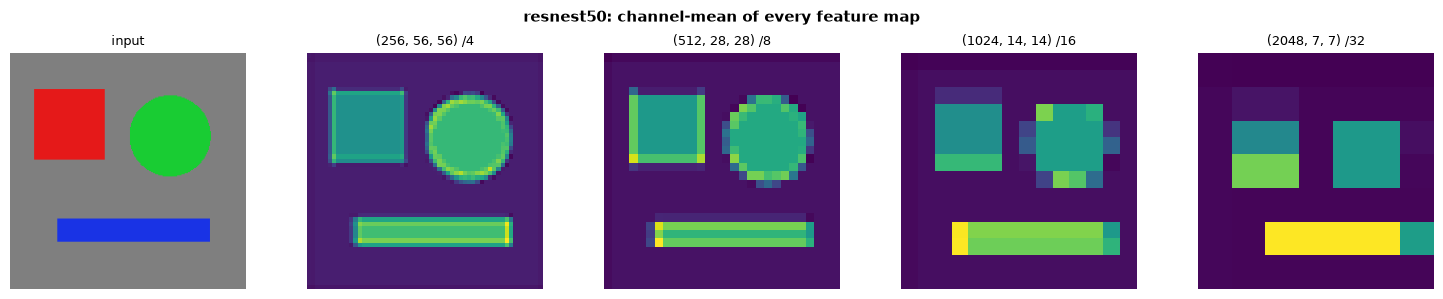

In [16]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [17]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [18]:
# ── Code Walkthrough ──────────────────────────────────────────────────────────
import torch

# 1. SplitAttentionConv2d — forward pass
sa = SplitAttentionConv2d(in_channels=64, out_channels=64, kernel_size=3, radix=2)
x  = torch.randn(2, 64, 28, 28)
y  = sa(x)
print('SplitAttentionConv2d(64→64, k=3, radix=2):')
print(f'  Input:  {tuple(x.shape)}')
print(f'  Output: {tuple(y.shape)}')

# 2. Attention weights are soft-max over radix, so they sum to 1
print('\n  Conv produces C×radix feature maps, then attention recombines them.')
print(f'  sa.conv output channels: {sa.conv.out_channels}  (= 64 × 2)')

# 3. ResNeSt Bottleneck
blk = ResNeStBottleneck(in_planes=256, planes=64)  # expands to 256
x2  = torch.randn(2, 256, 28, 28)
y2  = blk(x2)
print(f'\nResNeStBottleneck(256, 64): input={tuple(x2.shape)}, output={tuple(y2.shape)}')
print(f'  Params: {sum(p.numel() for p in blk.parameters()):,}')

SplitAttentionConv2d(64→64, k=3, radix=2):
  Input:  (2, 64, 28, 28)
  Output: (2, 64, 28, 28)

  Conv produces C×radix feature maps, then attention recombines them.
  sa.conv output channels: 128  (= 64 × 2)

ResNeStBottleneck(256, 64): input=(2, 256, 28, 28), output=(2, 256, 28, 28)
  Params: 76,864


In [19]:
# ── Usage Example ─────────────────────────────────────────────────────────────

for name in ['resnest50', 'resnest101']:
    b = build_vision_backbone(name)
    b.eval()
    x = torch.randn(1, 3, 224, 224)
    with torch.no_grad():
        out = b(x)
    print(f'{name}:')
    print(f'  pooled:       {tuple(out.pooled_output.shape)}')
    print(f'  feature_maps: {[tuple(f.shape) for f in out.feature_maps]}')
    print(f'  params:       {b.num_parameters():,}')

resnest50:
  pooled:       (1, 2048)
  feature_maps: [(1, 256, 56, 56), (1, 512, 28, 28), (1, 1024, 14, 14), (1, 2048, 7, 7)]
  params:       25,413,120


resnest101:
  pooled:       (1, 2048)
  feature_maps: [(1, 256, 56, 56), (1, 512, 28, 28), (1, 1024, 14, 14), (1, 2048, 7, 7)]
  params:       46,098,176


## References

| # | Citation |
|---|----------|
| [1] | Zhang, H., Wu, C., Zhang, Z., Zhu, Y., Zhang, Z., Lin, H., Sun, Y., He, T., Mueller, J., Manmatha, R., Li, M., & Smola, A. (2020). **ResNeSt: Split-Attention Networks.** arXiv:2004.08955. |
| [2] | Li, X., Wang, W., Hu, X., & Yang, J. (2019). **Selective Kernel Networks.** CVPR. arXiv:1903.06586. |
| [3] | Hu, J., Shen, L., & Sun, G. (2018). **Squeeze-and-Excitation Networks.** CVPR. arXiv:1709.01507. |
| [4] | He, K., Zhang, X., Ren, S., & Sun, J. (2016). **Deep Residual Learning for Image Recognition.** CVPR. arXiv:1512.03385. |
| [5] | Xie, S., Girshick, R., Dollár, P., Tu, Z., & He, K. (2017). **Aggregated Residual Transformations for Deep Neural Networks (ResNeXt).** CVPR. |

---
*Notebook: ResNeSt — HaleBlocks backbone family*  
*Architecture: `hale_core.nn.vision.cnn.resnest`*